# 04 — Conectividade funcional (AAL): viés de pipeline e classificadores

**Features:** correlação entre as séries de 114 regiões do atlas AAL (z de Fisher), 6441 pares por sujeito,
geradas por `src/connectivity.py`. ABIDE I processado pelo C-PAC (`filt_noglobal`), ADHD-200 pelo Athena.
ABIDE II não tem conectividade.

**Problema central:** TEA só vem do ABIDE e TDAH só do ADHD-200, e agora cada base também tem um **pipeline de
processamento diferente**. Antes de comparar TEA × TDAH, testamos se a conectividade denuncia a base entre controles.

**Plano**
1. Viés de pipeline/base entre controles.
2. Tarefas sem esse confundimento, dentro de cada base: TEA × Controle (ABIDE I) e TDAH × Controle (ADHD-200).
3. As três classes juntas (coorte pareada com imagem), lidas à luz do item 1.

**Validação:** `GroupKFold` por instituição (5 dobras), **3 repetições** (cada ajuste do XGBoost com 6441 features
leva ~15 s). Modelos: regressão logística L2 (C por validação interna), árvore (profundidade 3), Random Forest e
XGBoost. Código em `src/evaluation.py` (`make_models_conn`).

In [1]:
import sys
import warnings
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from evaluation import (CLASSES, RANDOM_STATE, confusion_table, make_models_conn, metrics_binary,
                        repeated_group_cv)
from matching import add_group, match_groups

warnings.filterwarnings("ignore")
FIG = ROOT / "results" / "figures"
sns.set_theme(style="whitegrid", context="notebook")
SEEDS = range(3)

npz = np.load(ROOT / "data" / "processed" / "connectivity_aal.npz", allow_pickle=True)
FC = pd.DataFrame(npz["X"], index=npz["subject_id"])
coorte = add_group(pd.read_csv(ROOT / "data" / "interim" / "cohort_7_21.csv")).set_index("subject_id")
img = coorte.loc[coorte.index.intersection(FC.index)].copy()
print(f"Conectividade: {FC.shape[0]} sujeitos × {FC.shape[1]} pares; na coorte 7–21 anos: {len(img)}")
pd.crosstab(img["release"], img["diagnosis"], margins=True)

Conectividade: 1819 sujeitos × 6441 pares; na coorte 7–21 anos: 1495


diagnosis,Controle,TDAH,TEA,All
release,,,,
ABIDE_I,387,0,345,732
ADHD200,440,323,0,763
All,827,323,345,1495


## 1. A conectividade denuncia a base (e o pipeline) entre controles?
Alvo = base de origem (ABIDE × ADHD-200), só controles. Duas versões das features:
- **bruta**: z de Fisher como sai do pipeline;
- **normalizada por sujeito**: cada vetor de conectividade centrado e escalado (média 0, DP 1) no próprio sujeito,
  o que remove diferenças globais de nível e escala entre pipelines.

Também repetimos dentro das 4 instituições presentes nas duas bases (NYU, KKI, OHSU, Pittsburgh), com validação
estratificada simples (a instituição é a mesma; muda a base e o pipeline). Acaso = 0,50.

In [2]:
def por_sujeito(X):
    X = np.asarray(X, dtype=float)
    return (X - X.mean(axis=1, keepdims=True)) / X.std(axis=1, keepdims=True)

ctrl = img[img.diagnosis == "Controle"]
y_base = (ctrl.dataset == "ABIDE").astype(int).to_numpy()
modelos_vies = {k: v for k, v in make_models_conn().items() if k in ["Regressão logística", "Random Forest"]}
compart = ["KKI", "NYU", "OHSU", "Pittsburgh"]
linhas = []
for nome_x in ["bruta", "normalizada por sujeito"]:
    X = FC.loc[ctrl.index].to_numpy()
    X = X if nome_x == "bruta" else por_sujeito(X)
    for nome_m, m in modelos_vies.items():
        r, _ = repeated_group_cv(m, X, y_base, ctrl.institution.to_numpy(), seeds=SEEDS,
                                 metric_fn=partial(metrics_binary, nomes=("ADHD200", "ABIDE")))
        linhas.append({"features": nome_x, "modelo": nome_m, "cenário": "todas as instituições (validação por instituição)",
                       "acc_bal": r.acc_balanceada.mean(), "dp": r.acc_balanceada.std(), "auc": r.auc.mean()})
        sel = ctrl.institution.isin(compart).to_numpy()
        p = cross_val_predict(m, X[sel], y_base[sel], method="predict_proba",
                              cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE))
        mb = metrics_binary(y_base[sel], p)
        linhas.append({"features": nome_x, "modelo": nome_m, "cenário": "só as 4 instituições compartilhadas",
                       "acc_bal": mb["acc_balanceada"], "dp": np.nan, "auc": mb["auc"]})
vies = pd.DataFrame(linhas)
print(f"Controles: {len(ctrl)} (ABIDE {y_base.sum()}, ADHD-200 {(1 - y_base).sum()})")
vies.round(3)

Controles: 827 (ABIDE 387, ADHD-200 440)


,features,modelo,cenário,acc_bal,dp,auc
0,bruta,Regressão logística,todas as instituições (validação por instituição),0.999,0.000,1.0
1,bruta,Regressão logística,só as 4 instituições compartilhadas,1.000,NaN,1.0
2,bruta,Random Forest,todas as instituições (validação por instituição),0.998,0.001,1.0
3,bruta,Random Forest,só as 4 instituições compartilhadas,0.996,NaN,1.0
4,normalizada por sujeito,Regressão logística,todas as instituições (validação por instituição),0.998,0.001,1.0
5,normalizada por sujeito,Regressão logística,só as 4 instituições compartilhadas,1.000,NaN,1.0
6,normalizada por sujeito,Random Forest,todas as instituições (validação por instituição),0.999,0.001,1.0
7,normalizada por sujeito,Random Forest,só as 4 instituições compartilhadas,1.000,NaN,1.0


## 2. Tarefas dentro de cada base (sem confundimento de pipeline)
Aqui o pipeline é o mesmo para casos e controles, então o que o modelo aprende não pode ser diferença de base.
Usamos todos os sujeitos com imagem da coorte 7–21 anos de cada base (classes balanceadas por peso).

In [3]:
def tarefa(base, positivo):
    d = img[(img.dataset == base) & img.diagnosis.isin(["Controle", positivo])]
    X = FC.loc[d.index].to_numpy()
    y = (d.diagnosis == positivo).astype(int).to_numpy()
    res = {}
    for nome, m in make_models_conn().items():
        r, _ = repeated_group_cv(m, X, y, d.institution.to_numpy(), seeds=SEEDS,
                                 metric_fn=partial(metrics_binary, nomes=("Controle", positivo)))
        res[nome] = r
    return d, res

tarefas = {}
for base, pos in [("ABIDE", "TEA"), ("ADHD200", "TDAH")]:
    d, res = tarefa(base, pos)
    tarefas[f"{pos} × Controle ({base})"] = res
    print(f"{pos} × Controle ({base}): {len(d)} sujeitos, {(d.diagnosis == pos).sum()} {pos}, "
          f"{d.institution.nunique()} instituições")

resumo_bin = pd.concat({t: pd.concat({n: r.drop(columns="semente").mean() for n, r in res.items()}, axis=1).T
                        for t, res in tarefas.items()})
resumo_bin.round(3)

TEA × Controle (ABIDE): 732 sujeitos, 345 TEA, 17 instituições


TDAH × Controle (ADHD200): 763 sujeitos, 323 TDAH, 7 instituições


acc_balanceada  sens_TEA  \
TEA × Controle (ABIDE)    Regressão logística           0.641     0.656   
                          Árvore de decisão             0.527     0.476   
                          Random Forest                 0.610     0.589   
                          XGBoost                       0.627     0.611   
TDAH × Controle (ADHD200) Regressão logística           0.443       NaN   
                          Árvore de decisão             0.424       NaN   
                          Random Forest                 0.405       NaN   
                          XGBoost                       0.426       NaN   

                                               espec_Controle    auc  \
TEA × Controle (ABIDE)    Regressão logística           0.626  0.691   
                          Árvore de decisão             0.578  0.534   
                          Random Forest                 0.631  0.663   
                          XGBoost                       0.643  0.677   
TDAH × Controle (ADHD200) Regressão logística           0.680  0.446   
                          Árvore de decisão             0.471  0.450   
                          Random Forest                 0.691  0.350   
                          XGBoost                       0.730  0.368   

                                               sens_TDAH  
TEA × Controle (ABIDE)    Regressão logística        NaN  
                          Árvore de decisão          NaN  
                          Random Forest              NaN  
                          XGBoost                    NaN  
TDAH × Controle (ADHD200) Regressão logística      0.206  
                          Árvore de decisão        0.378  
                          Random Forest            0.119  
                          XGBoost                  0.121

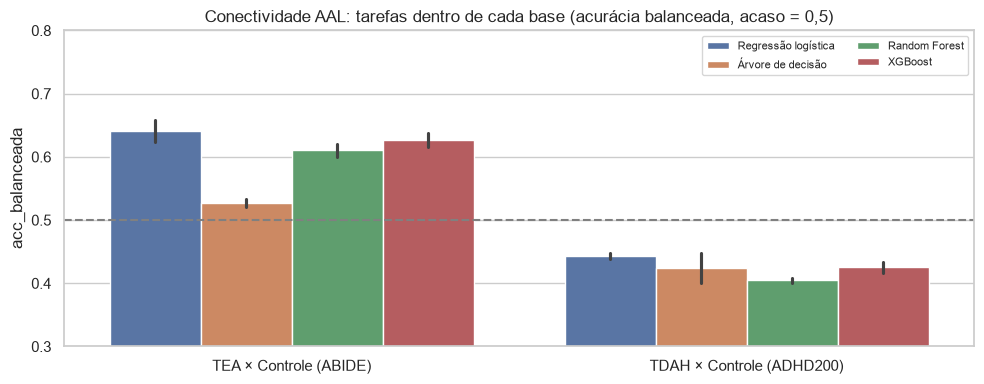

In [4]:
longo = pd.concat([r.assign(modelo=n, tarefa=t) for t, res in tarefas.items() for n, r in res.items()])
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(data=longo, x="tarefa", y="acc_balanceada", hue="modelo", errorbar="sd", ax=ax)
ax.axhline(0.5, ls="--", c="gray"); ax.set_ylim(0.3, 0.8); ax.set_xlabel("")
ax.set_title("Conectividade AAL: tarefas dentro de cada base (acurácia balanceada, acaso = 0,5)")
ax.legend(fontsize=8, ncol=2); plt.tight_layout(); plt.savefig(FIG / "04_conectividade_tarefas_binarias.png", dpi=150)

## 3. As três classes juntas (TEA × TDAH × Controle)
Coorte com imagem pareada por sexo e idade, como no notebook 02. **Atenção:** TEA só tem C-PAC e TDAH só tem
Athena; compare com o resultado da seção 1 antes de interpretar.

In [5]:
par = match_groups(img.reset_index(), age_bin=1.0, seed=RANDOM_STATE).set_index("subject_id")
print(par.grupo.value_counts().to_dict())
X3 = FC.loc[par.index].to_numpy()
y3 = par.diagnosis.map({c: i for i, c in enumerate(CLASSES)}).to_numpy()
res3, oof3 = {}, {}
for nome, m in make_models_conn().items():
    res3[nome], oof3[nome] = repeated_group_cv(m, X3, y3, par.institution.to_numpy(), seeds=SEEDS)
resumo3 = pd.concat({n: r.drop(columns="semente").agg(["mean", "std"]).T for n, r in res3.items()}, axis=1)
resumo3.round(3)

{'TEA (ABIDE)': 204, 'Controle (ABIDE)': 204, 'TDAH (ADHD200)': 204, 'Controle (ADHD200)': 204}


Regressão logística        Árvore de decisão         \
                                 mean    std              mean    std   
acc_balanceada                  0.639  0.010             0.572  0.010   
sens_Controle                   0.132  0.029             0.231  0.022   
sens_TDAH                       0.882  0.017             0.634  0.041   
sens_TEA                        0.904  0.025             0.850  0.022   
auc_macro_ovr                   0.717  0.007             0.657  0.003   
confusao_TEA_TDAH               0.000  0.000             0.023  0.010   

                  Random Forest        XGBoost         
                           mean    std    mean    std  
acc_balanceada            0.565  0.009   0.484  0.027  
sens_Controle             0.148  0.016   0.444  0.094  
sens_TDAH                 0.706  0.018   0.315  0.125  
sens_TEA                  0.842  0.010   0.693  0.054  
auc_macro_ovr             0.699  0.006   0.703  0.001  
confusao_TEA_TDAH         0.000  0.000   0.000  0.000

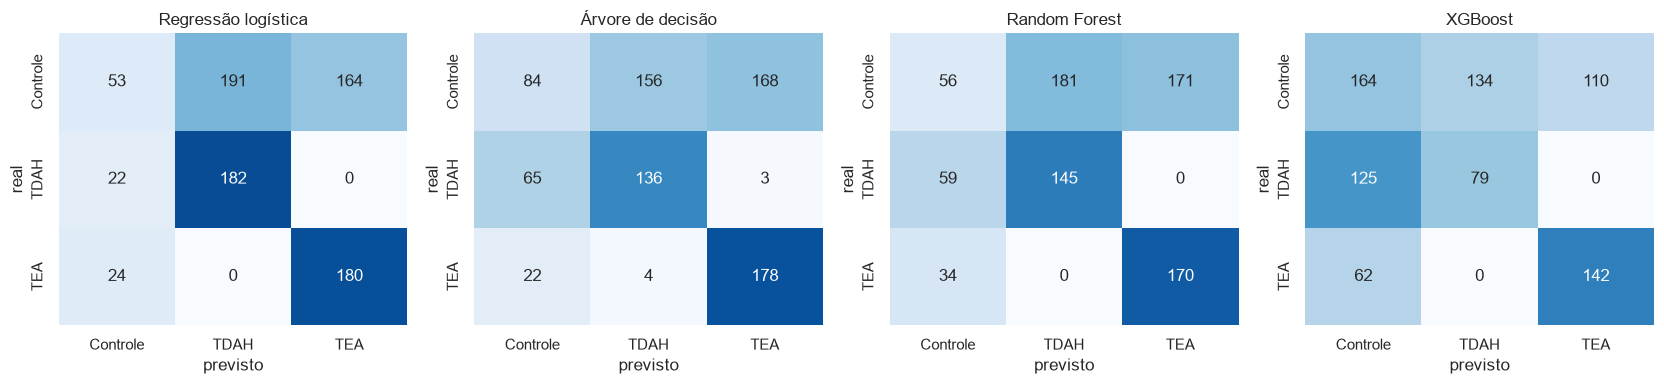

In [6]:
fig, ax = plt.subplots(1, len(oof3), figsize=(4.2 * len(oof3), 4))
for a, (nome, p) in zip(ax, oof3.items()):
    cm = confusion_table(y3, p)
    sns.heatmap(cm.div(cm.sum(axis=1), axis=0), annot=cm.values, fmt="d", cmap="Blues", vmin=0, vmax=1, cbar=False,
                ax=a, xticklabels=CLASSES, yticklabels=CLASSES)
    a.set_title(nome); a.set_xlabel("previsto"); a.set_ylabel("real")
fig.tight_layout(); fig.savefig(FIG / "04_conectividade_3classes_confusao.png", dpi=150)

## 4. Leitura dos resultados (execução de 25/11/2026)

**1. A conectividade identifica a base com acurácia quase perfeita.** Entre controles, regressão logística e Random
Forest acertam a base com acurácia balanceada de **0,998–1,000** (AUC 1,0). Isso vale com validação por instituição,
dentro das 4 instituições presentes nas duas bases e também com a conectividade normalizada por sujeito. As
diferenças entre os pipelines (C-PAC no ABIDE, Athena no ADHD-200) dominam o sinal.

**2. Por isso, a análise de três classes não é interpretável.** Na coorte pareada com imagem (204 por grupo), nenhum
caso de TEA é classificado como TDAH nem o contrário (confusão TEA↔TDAH = 0), enquanto os controles se dividem entre
"TEA" e "TDAH" conforme a base. A acurácia de 0,64 da regressão logística mede o pipeline, não o diagnóstico.

**3. Dentro do ABIDE I (mesmo pipeline), há sinal para TEA × Controle.**

| Modelo | Acurácia balanceada | Sens. TEA | Espec. | AUC |
|---|---|---|---|---|
| **Regressão logística** | **0,64** | 0,66 | 0,63 | 0,69 |
| XGBoost | 0,63 | 0,61 | 0,64 | 0,68 |
| Random Forest | 0,61 | 0,59 | 0,63 | 0,66 |
| Árvore de decisão | 0,53 | 0,48 | 0,58 | 0,53 |

732 sujeitos, 17 instituições, validação por instituição. É compatível com a literatura do ABIDE com validação entre
sítios (~0,60–0,70). Aqui os **comitês (RF, XGBoost) superam a árvore** (+0,08 a +0,10), mas **não superam a
regressão logística**.

**4. Dentro do ADHD-200 (mesmo pipeline), TDAH × Controle fica abaixo do acaso** (0,40–0,44; AUC 0,35–0,45).
Resultado abaixo do acaso com validação por instituição indica efeito de sítio: a proporção de TDAH varia muito entre
as 7 instituições (Pittsburgh e WashU quase só controles, NYU majoritariamente TDAH). O modelo aprende "sítio" e,
ao prever uma instituição nova, erra sistematicamente. A literatura do ADHD-200 também relata desempenho baixo.

**Implicações para o projeto**
- Com os dados públicos atuais, **não é possível comparar TEA × TDAH pela conectividade**: cada transtorno vem de
  uma base com pipeline próprio, e o pipeline é perfeitamente identificável. Só uma base com os dois diagnósticos no
  mesmo protocolo (HBN) resolve isso.
- O resultado válido para a apresentação é TEA × Controle no ABIDE I, em que a hipótese "comitê > árvore" se
  confirma, mas a regressão logística empata ou supera os comitês.
- Próximos passos possíveis: harmonização por instituição sem rótulos (ex.: padronizar cada feature dentro da
  instituição) para o ADHD-200; combinar fenótipo + conectividade; refazer as séries das duas bases com um mesmo
  pipeline (fMRIPrep do S3 + extração própria), o que exige muito download e processamento.

**Limitações:** 3 repetições de validação; hiperparâmetros fixos para árvore, RF e XGBoost; sem controle de
movimento além do QC dos pipelines; conectividade só por correlação de Pearson.